In [39]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from lifelines import AalenJohansenFitter, CoxPHFitter
from lifelines.statistics import proportional_hazard_test

path = "misc_c_surveillance.csv"
surv = pd.read_csv(path)   # raw data: survival keeps Still admitted / Unknown

In [40]:
surv['time'] = pd.to_numeric(surv['Hospital Length of Stay (Days)'], errors='coerce')
surv = surv[surv['time'].notna() & (surv['time'] >= 0)].copy()
surv['time'] = surv['time'].replace(0, 0.5)       # same-day stays: 0 days breaks Cox

# 1 = discharged (event of interest), 2 = died (competing), 0 = censored
surv['event'] = surv['Outcome'].map({'Discharged': 1, 'Died': 2,
                                     'Still admitted': 0, 'Unknown': 0})
surv = surv[surv['Sex'] != 'Unknown']             # n=3, same as main model
print(surv['event'].value_counts().rename({1: 'Discharged', 2: 'Died', 0: 'Censored'}))

event
Discharged    8639
Censored       125
Died            75
Name: count, dtype: int64


In [41]:
r = surv[['White Race', 'Black Race', 'Other Race']].astype(int)
surv['Race'] = np.select(
    [r['White Race'].eq(1), r['Black Race'].eq(1), r['Other Race'].eq(1)],
    ['White', 'Black', 'Other'], default='Unknown')
surv['Census Region'] = surv['Census Region'].replace('data suppressed', 'Suppressed')

for c in ['ICU Level of Care', 'Shock', 'Intubation or Mechanical Ventilation',
          'Severe Cardiac Involvement', 'Obesity', 'Chronic Lung Disease',
          'All Other Comorbidities']:
    surv[c] = surv[c].fillna(False).astype(int)

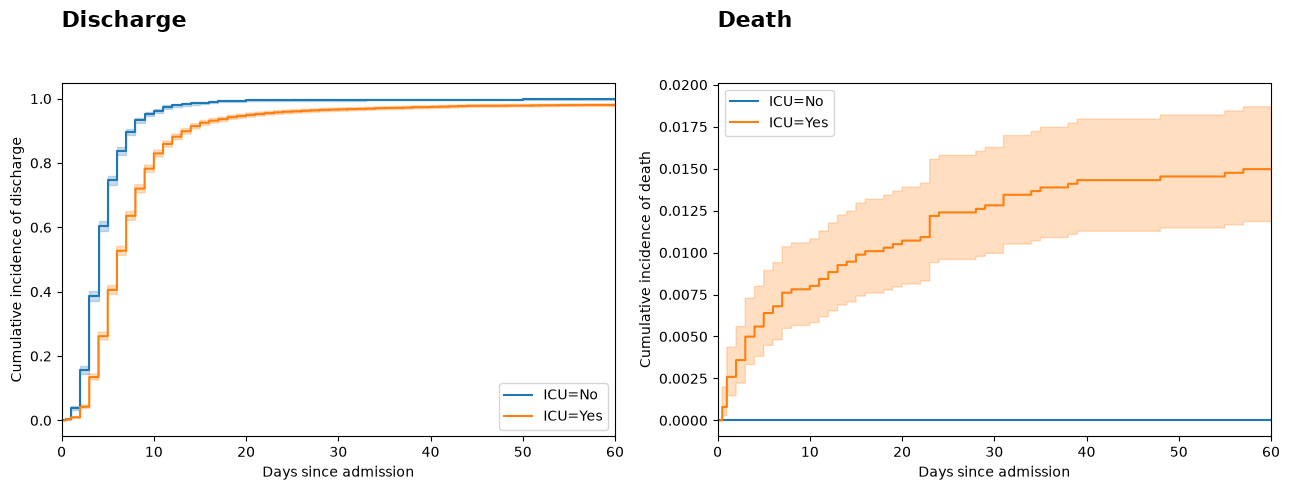

ICU=0: median time to discharge = 4.0 days
ICU=1: median time to discharge = 6.0 days


In [42]:
# Kaplan–Meier is wrong here (treats deaths as censored → overstates discharge)
import warnings
warnings.filterwarnings('ignore',message="Tied event times")
plt.style.use('default')
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, (code, lab) in enumerate([(1, 'Discharge'), (2, 'Death')]):
    for icu, g in surv.groupby('ICU Level of Care'):
        aj = AalenJohansenFitter(jitter_level=0.0001, seed=42)
        aj.fit(g['time'], g['event'], event_of_interest=code)
        aj.plot(ax=ax[k], label=f"ICU={'Yes' if icu else 'No'}")
    ax[k].set_xlim(0, 60)
    ax[k].set_xlabel('Days since admission')
    ax[k].set_ylabel(f'Cumulative incidence of {lab.lower()}')
    ax[k].set_title(lab, loc='left', fontsize=16, fontweight='bold', pad=40)
plt.tight_layout(); plt.show()

# Median time to discharge (CIF reaches 0.5)
for icu, g in surv.groupby('ICU Level of Care'):
    aj = AalenJohansenFitter(jitter_level=0.0001, seed=42).fit(g['time'], g['event'], event_of_interest=1)
    cif = aj.cumulative_density_.iloc[:, 0]
    print(f"ICU={icu}: median time to discharge = {cif[cif >= 0.5].index.min():.1f} days")

In [43]:
import re
from IPython.display import display

# HR > 1 → discharged FASTER (shorter LOS); HR < 1 → longer stay
surv['discharged'] = (surv['event'] == 1).astype(int)

base = ("C(Q('Age Group'), Treatment('5-11 years')) + C(Sex, Treatment('Male')) + "
        "C(Race, Treatment('White')) + C(Ethnicity, Treatment('Not Hispanic or Latino')) + "
        "C(Q('Census Region'), Treatment('South')) + "
        "Q('Obesity') + Q('Chronic Lung Disease') + Q('All Other Comorbidities')")
severity = (" + Q('ICU Level of Care') + Q('Shock') + "
            "Q('Intubation or Mechanical Ventilation') + Q('Severe Cardiac Involvement')")

cols = ['Age Group', 'Sex', 'Race', 'Ethnicity', 'Census Region', 'Obesity',
        'Chronic Lung Disease', 'All Other Comorbidities', 'ICU Level of Care', 'Shock',
        'Intubation or Mechanical Ventilation', 'Severe Cardiac Involvement']

def fit_cox(formula):
    return CoxPHFitter().fit(surv[['time', 'discharged'] + cols], duration_col='time',
                             event_col='discharged', formula=formula)

cox1 = fit_cox(base)
cox2 = fit_cox(base + severity)

# ── Readable variable names ───────────────────────────────
def clean(name):
    m = re.match(r"C\((?:Q\(')?([^',)]+)'?\)?, Treatment\('[^']+'\)\)\[T\.(.+)\]", name)
    if m:
        return f"{m.group(1)}: {m.group(2)}"
    m = re.match(r"Q\('(.+)'\)", name)
    return m.group(1) if m else name

def hr_column(model):
    out = {}
    for name, r in model.summary.iterrows():
        txt = f"{r['exp(coef)']:.2f} ({r['exp(coef) lower 95%']:.2f}–{r['exp(coef) upper 95%']:.2f})"
        out[clean(name)] = f"<b>{txt}</b>" if r['p'] < 0.05 else txt
    return pd.Series(out)

m1, m2 = hr_column(cox1), hr_column(cox2)
table = pd.DataFrame({'Model 1: baseline':          m1.reindex(m2.index),
                      'Model 2: severity-adjusted': m2}).fillna('—')
table.index.name = 'Variable'
table = table.reset_index()

display(table.style
        .hide(axis='index')
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption(f"Cox models for time to discharge — HR (95% CI); HR < 1 = slower discharge (longer stay); bold = p < 0.05<br>"
                     f"C-index: Model 1 = {cox1.concordance_index_:.3f}, Model 2 = {cox2.concordance_index_:.3f}"))

Variable,Model 1: baseline,Model 2: severity-adjusted
Age Group: 1-4 years,1.09 (1.03–1.15),0.97 (0.92–1.03)
Age Group: 12-15 years,0.84 (0.79–0.89),0.93 (0.87–0.98)
Age Group: 16-20 years,0.72 (0.66–0.77),0.77 (0.71–0.83)
Age Group: <1 year,1.01 (0.89–1.14),0.87 (0.77–0.99)
Sex: Female,1.01 (0.97–1.05),1.02 (0.98–1.07)
Race: Black,0.74 (0.71–0.78),0.81 (0.77–0.86)
Race: Other,0.90 (0.84–0.95),0.90 (0.85–0.96)
Race: Unknown,0.90 (0.82–1.00),0.95 (0.87–1.05)
Ethnicity: Hispanic or Latino,0.89 (0.84–0.94),0.88 (0.83–0.93)
Ethnicity: Unknown,0.90 (0.83–0.98),0.87 (0.80–0.95)


**How to read:** HR < 1 = slower discharge (longer stay). Model 2 adds ICU care, shock, intubation and severe cardiac involvement.

- Older adolescents, Black and Hispanic children, children with comorbidities and children with obesity were discharged more slowly, in both models.
- Infants (<1 year) had longer stays only after adjusting for severity (HR 0.87).
- Adding severity raised the C-index from 0.58 to 0.69, so clinical severity explains much more of the variation in time to discharge than demographics do.

In [44]:
ph = proportional_hazard_test(cox2, surv[['time', 'discharged'] + cols], time_transform='rank')
ph_tbl = ph.summary[['test_statistic', 'p']].copy()
ph_tbl.index = [clean(i) for i in ph_tbl.index]
ph_tbl = ph_tbl.sort_values('test_statistic', ascending=False)

sig = ph_tbl['p'] < 0.05
bold = lambda text, s: f"<b>{text}</b>" if s else text
ph_tbl['Test statistic'] = [bold(f"{t:.1f}", s) for t, s in zip(ph_tbl['test_statistic'], sig)]
ph_tbl['p-value'] = [bold('<0.001' if p < 0.001 else f"{p:.3f}", s) for p, s in zip(ph_tbl['p'], sig)]
ph_tbl = ph_tbl[['Test statistic', 'p-value']].rename_axis('Variable').reset_index()

display(ph_tbl.style
        .hide(axis='index')
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption('Proportional hazards test (bold = p < 0.05, hazard ratio changes over time)'))

Variable,Test statistic,p-value
Intubation or Mechanical Ventilation,42.7,<0.001
Severe Cardiac Involvement,40.9,<0.001
Age Group: <1 year,40.7,<0.001
Shock,34.3,<0.001
ICU Level of Care,29.9,<0.001
Census Region: Midwest,12.9,<0.001
Race: Black,10.1,0.002
Ethnicity: Hispanic or Latino,8.7,0.003
All Other Comorbidities,5.6,0.018
Census Region: Northeast,4.1,0.043


Proportional hazards check

In [45]:
# Fix: stratify on the severity markers that break PH
cph_s = CoxPHFitter()
cph_s.fit(surv[['time', 'discharged'] + cols], duration_col='time', event_col='discharged',
          formula=base + " + Q('Shock') + Q('Severe Cardiac Involvement')",
          strata=['ICU Level of Care', 'Intubation or Mechanical Ventilation'])
strat = hr_column(cph_s).rename('HR (95% CI), stratified by ICU × intubation')
display(strat.rename_axis('Variable').reset_index().style
        .hide(axis='index')
        .set_properties(**{'text-align': 'left', 'padding': '6px 18px', 'font-size': '15px'})
        .set_table_styles([{'selector': 'th', 'props': 'text-align: left; padding: 6px 18px; font-size: 15px;'},
                           {'selector': 'caption', 'props': 'text-align: left; font-weight: bold; font-size: 17px; padding-bottom: 10px;'}])
        .set_caption('Model 2s — Cox model stratified by ICU care × intubation (bold = p < 0.05)'))

Variable,"HR (95% CI), stratified by ICU × intubation"
Age Group: 1-4 years,0.97 (0.92–1.03)
Age Group: 12-15 years,0.92 (0.87–0.98)
Age Group: 16-20 years,0.77 (0.71–0.83)
Age Group: <1 year,0.92 (0.81–1.04)
Sex: Female,1.01 (0.97–1.06)
Race: Black,0.82 (0.77–0.86)
Race: Other,0.89 (0.84–0.95)
Race: Unknown,0.93 (0.85–1.03)
Ethnicity: Hispanic or Latino,0.89 (0.84–0.94)
Ethnicity: Unknown,0.90 (0.83–0.98)


Fix: Model 2s, stratified by ICU care × intubation

**Proportional hazards check**

- The Cox model assumes each hazard ratio stays the **same over the whole stay**. The test (p < 0.05) shows where this does not hold.
- It fails most strongly for the **severity markers**: intubation, severe cardiac involvement, shock, ICU care, and age < 1 year. Their effect on discharge changes over time, for example by being strongest in the first days of the stay.
- Smaller departures appear for Midwest region, Black race, Hispanic ethnicity and other comorbidities. With almost 8,800 patients, the test flags even very small changes, so these are less important.

**Fix: Model 2s, stratified by ICU care × intubation**

- Each ICU × intubation group gets its **own baseline hazard**, so the model no longer assumes these two have a constant effect.
- The other results are **almost unchanged** from Model 2: age 16–20 HR **0.77**, Black race **0.82**, Hispanic **0.89**, other comorbidities **0.70**, obesity **0.93**.
- Age < 1 year is **no longer significant** (HR 0.92, 0.81–1.04). Its earlier effect was partly explained by infants' different ICU and ventilation patterns.
- **Conclusion:** the main findings are robust to the proportional hazards violation.

In [46]:
surv['died'] = (surv['event'] == 2).astype(int)
print(pd.crosstab(surv['ICU Level of Care'], surv['died']))
# Every death had ICU care → ICU can't be in this model (HR → infinity).
# 75 deaths support only a few predictors, so keep it small.
cph_d = CoxPHFitter().fit(surv[['time', 'died', 'Shock',
                                'Intubation or Mechanical Ventilation', 'All Other Comorbidities']],
                          duration_col='time', event_col='died')
out = cph_d.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
out.columns = ['HR', 'low', 'high', 'p']
print(f"Cause-specific Cox — DEATH (events={surv['died'].sum()})")
print(out.round(3).to_string())

died                  0   1
ICU Level of Care          
0                  3828   0
1                  4936  75
Cause-specific Cox — DEATH (events=75)
                                          HR     low    high      p
covariate                                                          
Shock                                  1.454   0.671   3.152  0.343
Intubation or Mechanical Ventilation  28.304  12.589  63.636  0.000
All Other Comorbidities                2.090   1.296   3.372  0.003
